<a href="https://colab.research.google.com/github/npeyton/ml_materials/blob/main/Nielsen_Chapter3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Chapter 3 Code - Cross Entropy cost function, Softmax

In [1]:
#getting the code from the first lesson.
!git clone https://github.com/unexploredtest/neural-networks-and-deep-learning.git
%cd neural-networks-and-deep-learning/src
import mnist_loader
training_data, validation_data, test_data = mnist_loader.load_data_wrapper()

Cloning into 'neural-networks-and-deep-learning'...
remote: Enumerating objects: 1227, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 1227 (delta 21), reused 17 (delta 17), pack-reused 1175 (from 3)
Receiving objects: 100% (1227/1227), 20.45 MiB | 12.41 MiB/s, done.
Resolving deltas: 100% (606/606), done.
/content/neural-networks-and-deep-learning/src


In [2]:
import network2
net = network2.Network([784, 30, 10], cost=network2.CrossEntropyCost)
net.large_weight_initializer()
net.SGD(training_data, 30, 10, 0.5, evaluation_data=test_data,
monitor_evaluation_accuracy=True)

Epoch 0 training complete
Accuracy on evaluation data: 9101 / 10000
Epoch 1 training complete
Accuracy on evaluation data: 9312 / 10000
Epoch 2 training complete
Accuracy on evaluation data: 9350 / 10000
Epoch 3 training complete
Accuracy on evaluation data: 9382 / 10000
Epoch 4 training complete
Accuracy on evaluation data: 9403 / 10000
Epoch 5 training complete
Accuracy on evaluation data: 9404 / 10000
Epoch 6 training complete
Accuracy on evaluation data: 9437 / 10000
Epoch 7 training complete
Accuracy on evaluation data: 9428 / 10000
Epoch 8 training complete
Accuracy on evaluation data: 9445 / 10000
Epoch 9 training complete
Accuracy on evaluation data: 9440 / 10000
Epoch 10 training complete
Accuracy on evaluation data: 9424 / 10000
Epoch 11 training complete
Accuracy on evaluation data: 9463 / 10000
Epoch 12 training complete
Accuracy on evaluation data: 9463 / 10000
Epoch 13 training complete
Accuracy on evaluation data: 9449 / 10000
Epoch 14 training complete
Accuracy on evalu

([],
 [9101,
  9312,
  9350,
  9382,
  9403,
  9404,
  9437,
  9428,
  9445,
  9440,
  9424,
  9463,
  9463,
  9449,
  9475,
  9471,
  9454,
  9471,
  9474,
  9481,
  9476,
  9457,
  9472,
  9482,
  9491,
  9482,
  9488,
  9497,
  9486,
  9493],
 [],
 [])

Softmax Cost Function. - Can allow you to interperet the activations of the final layer of the network as probabilities that sum to 1, a probability distribution. And thus each final layer neuron represents the probability that that neuron is the correct answer.

In [3]:
# Showing that using the sigmoid function, the output activations (final layer activations) wont always sum to 1.
import network

training_data, validation_data, test_data = mnist_loader.load_data_wrapper()
training_data = list(training_data)
test_data = list(test_data)

net = network.Network([784, 30, 10])
net.SGD(training_data, 30, 10, 3.0, test_data=test_data)

/content/neural-networks-and-deep-learning/src/network.py:134: SyntaxWarning: invalid escape sequence '\p'
  """Return the vector of partial derivatives \partial C_x /


Epoch 0: 9065 / 10000, took 6.27 seconds
Epoch 1: 9218 / 10000, took 7.71 seconds
Epoch 2: 9315 / 10000, took 6.43 seconds
Epoch 3: 9362 / 10000, took 7.41 seconds
Epoch 4: 9369 / 10000, took 6.85 seconds
Epoch 5: 9367 / 10000, took 7.06 seconds
Epoch 6: 9374 / 10000, took 7.24 seconds
Epoch 7: 9409 / 10000, took 6.56 seconds
Epoch 8: 9453 / 10000, took 7.75 seconds
Epoch 9: 9398 / 10000, took 6.31 seconds
Epoch 10: 9445 / 10000, took 7.70 seconds
Epoch 11: 9440 / 10000, took 6.29 seconds
Epoch 12: 9456 / 10000, took 7.70 seconds
Epoch 13: 9420 / 10000, took 6.26 seconds
Epoch 14: 9461 / 10000, took 7.72 seconds
Epoch 15: 9439 / 10000, took 6.26 seconds
Epoch 16: 9452 / 10000, took 7.73 seconds
Epoch 17: 9455 / 10000, took 6.26 seconds
Epoch 18: 9470 / 10000, took 7.70 seconds
Epoch 19: 9488 / 10000, took 6.34 seconds
Epoch 20: 9484 / 10000, took 7.54 seconds
Epoch 21: 9472 / 10000, took 6.68 seconds
Epoch 22: 9479 / 10000, took 7.17 seconds
Epoch 23: 9474 / 10000, took 7.12 seconds
Ep

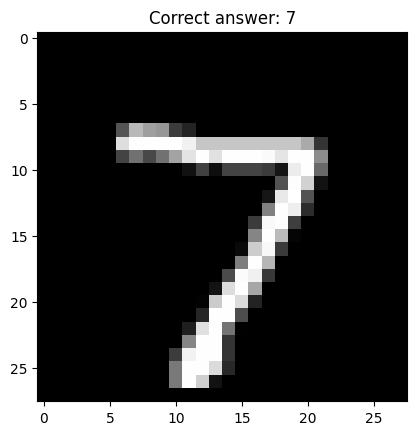

0: 0.0000  
1: 0.0000  
2: 0.0000  
3: 0.0000  
4: 0.0000  
5: 0.0000  
6: 0.0000  
7: 1.0000  ███████████████████████████████████████
8: 0.0000  
9: 0.0000  
1.0000102310404577
1.0000102310404577


In [4]:
import matplotlib.pyplot as plt
import numpy as np

x, y = test_data[0]          # first test image and its correct digit

plt.imshow(x.reshape(28, 28), cmap="gray")
plt.title(f"Correct answer: {y}")
plt.show()

output = net.feedforward(x)  # the 10 final-layer activations

for digit in range(10):
    value = output[digit][0]
    bar = "█" * int(value * 40)
    print(f"{digit}: {value:.4f}  {bar}")
#total is more than 1
total = 0
for digit in range(10):
  value = output[digit][0]
  sum = value + total
  total = sum
print (total)
#Same thing in one line
print(np.sum(output))

Not a probability Distribution bc Sum(output)>1

In [5]:
import mnist_loader
training_data, validation_data, test_data = mnist_loader.load_data_wrapper()
import network2
net = network2.Network([784, 30, 10], cost=network2.CrossEntropyCost)
net.large_weight_initializer()
net.SGD(training_data[:1000], 10, 10, 0.5, evaluation_data=test_data, monitor_evaluation_accuracy=True, monitor_training_cost=True)

Epoch 0 training complete
Cost on training data: 1.8787818144214739
Accuracy on evaluation data: 5488 / 10000
Epoch 1 training complete
Cost on training data: 1.3696077995284448
Accuracy on evaluation data: 6455 / 10000
Epoch 2 training complete
Cost on training data: 1.1190209554150223
Accuracy on evaluation data: 6872 / 10000
Epoch 3 training complete
Cost on training data: 0.8954311464748494
Accuracy on evaluation data: 7317 / 10000
Epoch 4 training complete
Cost on training data: 0.8043130401274502
Accuracy on evaluation data: 7355 / 10000
Epoch 5 training complete
Cost on training data: 0.7280972710180432
Accuracy on evaluation data: 7451 / 10000
Epoch 6 training complete
Cost on training data: 0.5944967272106787
Accuracy on evaluation data: 7768 / 10000
Epoch 7 training complete
Cost on training data: 0.5159675445828835
Accuracy on evaluation data: 7865 / 10000
Epoch 8 training complete
Cost on training data: 0.4726438883032498
Accuracy on evaluation data: 7810 / 10000
Epoch 9 tr

([],
 [5488, 6455, 6872, 7317, 7355, 7451, 7768, 7865, 7810, 7876],
 [np.float64(1.8787818144214739),
  np.float64(1.3696077995284448),
  np.float64(1.1190209554150223),
  np.float64(0.8954311464748494),
  np.float64(0.8043130401274502),
  np.float64(0.7280972710180432),
  np.float64(0.5944967272106787),
  np.float64(0.5159675445828835),
  np.float64(0.4726438883032498),
  np.float64(0.42387713389018805)],
 [])

In [6]:
import mnist_loader
training_data, validation_data, test_data = mnist_loader.load_data_wrapper()

Handwriting Recognition

In [7]:

# defining the Cross Entropy cost Function.
class CrossEntropyCost(object):

    @staticmethod
    def fn(a, y):
        return np.sum(np.nan_to_num(-y*np.log(a)-(1-y)*np.log(1-a)))

    @staticmethod
    def delta(z, a, y):
        return (a-y)
# defining the Quadratic cost Function.

class QuadraticCost(object):

    @staticmethod
    def fn(a, y):
        return 0.5*np.linalg.norm(a-y)**2

    @staticmethod
    def delta(z, a, y):
        return (a-y) * sigmoid_prime(z)


#defining our neural Network function.
class Network(object):

    def __init__(self, sizes, cost=CrossEntropyCost):
        self.num_layers = len(sizes)
        self.sizes = sizes
        self.default_weight_initializer()
        self.cost=cost

    def default_weight_initializer(self):
        self.biases = [np.random.randn(y, 1) for y in self.sizes[1:]]
        self.weights = [np.random.randn(y, x)/np.sqrt(x) for x, y in zip(self.sizes[:-1], self.sizes[1:])]
        def feedforward(self, a):
          """ Return the output of the network if ``a`` is input."""
        for b, w in zip(self.biases, self.weights):
            a = sigmoid(np.dot(w, a)+b)
        return a

    def SGD(self, training_data, epochs, mini_batch_size, eta,
            lmbda = 0.0,
            evaluation_data=None,
            monitor_evaluation_cost=False,
            monitor_evaluation_accuracy=False,
            monitor_training_cost=False,
            monitor_training_accuracy=False):

      if evaluation_data: n_data = len(evaluation_data)
      n = len(training_data)
      evaluation_cost, evaluation_accuracy = [], []
      training_cost, training_accuracy = [], []
      for j in xrange(epochs):
            random.shuffle(training_data)
            mini_batches = [
                  training_data[k:k+mini_batch_size]
                  for k in xrange(0, n, mini_batch_size)]
            for mini_batch in mini_batches:
                  self.update_mini_batch(
                      mini_batch, eta, lmbda, len(training_data))
            print ("Epoch %s training complete" % j)
            if monitor_training_cost:
                  cost = self.total_cost(training_data, lmbda)
                  training_cost.append(cost)
                  print ("Cost on training data: {}").format(cost)
            if monitor_training_accuracy:
                  accuracy = self.accuracy(training_data, convert=True)
                  training_accuracy.append(accuracy)
                  print ("Accuracy on training data: {} / {}").format(
                      accuracy, n)
            if monitor_evaluation_cost:
                  cost = self.total_cost(evaluation_data, lmbda, convert=True)
                  evaluation_cost.append(cost)
                  print ("Cost on evaluation data: {}").format(cost)
            if monitor_evaluation_accuracy:
                  accuracy = self.accuracy(evaluation_data)
                  evaluation_accuracy.append(accuracy)
                  print ("Accuracy on evaluation data: {} / {}").format(
                      self.accuracy(evaluation_data), n_data)
            print
      return evaluation_cost, evaluation_accuracy, training_cost, training_accuracy

      def update_mini_batch(self, mini_batch, eta, lmbda, n):
        """Update the network's weights and biases by applying gradient
        descent using backpropagation to a single mini batch.  The
        ``mini_batch`` is a list of tuples ``(x, y)``, ``eta`` is the
        learning rate, ``lmbda`` is the regularization parameter, and
        ``n`` is the total size of the training data set.

        """
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        for x, y in mini_batch:
            delta_nabla_b, delta_nabla_w = self.backprop(x, y)
            nabla_b = [nb+dnb for nb, dnb in zip(nabla_b, delta_nabla_b)]
            nabla_w = [nw+dnw for nw, dnw in zip(nabla_w, delta_nabla_w)]
        self.weights = [(1-eta*(lmbda/n))*w-(eta/len(mini_batch))*nw
                        for w, nw in zip(self.weights, nabla_w)]
        self.biases = [b-(eta/len(mini_batch))*nb
                       for b, nb in zip(self.biases, nabla_b)]

    def backprop(self, x, y):
        """Return a tuple ``(nabla_b, nabla_w)`` representing the
        gradient for the cost function C_x.  ``nabla_b`` and
        ``nabla_w`` are layer-by-layer lists of numpy arrays, similar
        to ``self.biases`` and ``self.weights``."""
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        # feedforward
        activation = x
        activations = [x] # list to store all the activations, layer by layer
        zs = [] # list to store all the z vectors, layer by layer
        for b, w in zip(self.biases, self.weights):
            z = np.dot(w, activation)+b
            zs.append(z)
            activation = sigmoid(z)
            activations.append(activation)
        # backward pass
        delta = (self.cost).delta(zs[-1], activations[-1], y)
        nabla_b[-1] = delta
        nabla_w[-1] = np.dot(delta, activations[-2].transpose())
        # Note that the variable l in the loop below is used a little
        # differently to the notation in Chapter 2 of the book.  Here,
        # l = 1 means the last layer of neurons, l = 2 is the
        # second-last layer, and so on.  It's a renumbering of the
        # scheme in the book, used here to take advantage of the fact
        # that Python can use negative indices in lists.
        for l in xrange(2, self.num_layers):
            z = zs[-l]
            sp = sigmoid_prime(z)
            delta = np.dot(self.weights[-l+1].transpose(), delta) * sp
            nabla_b[-l] = delta
            nabla_w[-l] = np.dot(delta, activations[-l-1].transpose())
        return (nabla_b, nabla_w)

    def accuracy(self, data, convert=False):
        """Return the number of inputs in ``data`` for which the neural
        network outputs the correct result. The neural network's
        output is assumed to be the index of whichever neuron in the
        final layer has the highest activation.

        The flag ``convert`` should be set to False if the data set is
        validation or test data (the usual case), and to True if the
        data set is the training data. The need for this flag arises
        due to differences in the way the results ``y`` are
        represented in the different data sets.  In particular, it
        flags whether we need to convert between the different
        representations.  It may seem strange to use different
        representations for the different data sets.  Why not use the
        same representation for all three data sets?  It's done for
        efficiency reasons -- the program usually evaluates the cost
        on the training data and the accuracy on other data sets.
        These are different types of computations, and using different
        representations speeds things up.  More details on the
        representations can be found in
        mnist_loader.load_data_wrapper.

        """
        if convert:
            results = [(np.argmax(self.feedforward(x)), np.argmax(y))
                       for (x, y) in data]
        else:
            results = [(np.argmax(self.feedforward(x)), y)
                        for (x, y) in data]
        return sum(int(x == y) for (x, y) in results)

    def total_cost(self, data, lmbda, convert=False):
        """Return the total cost for the data set ``data``.  The flag
        ``convert`` should be set to False if the data set is the
        training data (the usual case), and to True if the data set is
        the validation or test data.  See comments on the similar (but
        reversed) convention for the ``accuracy`` method, above.
        """
        cost = 0.0
        for x, y in data:
            a = self.feedforward(x)
            if convert: y = vectorized_result(y)
            cost += self.cost.fn(a, y)/len(data)
        cost += 0.5*(lmbda/len(data))*sum(
            np.linalg.norm(w)**2 for w in self.weights)
        return cost

    def save(self, filename):
        """Save the neural network to the file ``filename``."""
        data = {"sizes": self.sizes,
                "weights": [w.tolist() for w in self.weights],
                "biases": [b.tolist() for b in self.biases],
                "cost": str(self.cost.__name__)}
        f = open(filename, "w")
        json.dump(data, f)
        f.close()

#### Loading a Network
def load(filename):
    """Load a neural network from the file ``filename``.  Returns an
    instance of Network.

    """
    f = open(filename, "r")
    data = json.load(f)
    f.close()
    cost = getattr(sys.modules[__name__], data["cost"])
    net = Network(data["sizes"], cost=cost)
    net.weights = [np.array(w) for w in data["weights"]]
    net.biases = [np.array(b) for b in data["biases"]]
    return net

#### Miscellaneous functions
def vectorized_result(j):
    """Return a 10-dimensional unit vector with a 1.0 in the j'th position
    and zeroes elsewhere.  This is used to convert a digit (0...9)
    into a corresponding desired output from the neural network.

    """
    e = np.zeros((10, 1))
    e[j] = 1.0
    return e

def sigmoid(z):
    """The sigmoid function."""
    return 1.0/(1.0+np.exp(-z))

def sigmoid_prime(z):
    """Derivative of the sigmoid function."""
    return sigmoid(z)*(1-sigmoid(z))


In [8]:
import mnist_loader
training_data, validation_data, test_data = mnist_loader.load_data_wrapper()
import network2
net = network2.Network([784, 30, 10], cost=network2.CrossEntropyCost)
net.SGD(training_data, 30, 10, 0.5, lmbda = 5.0,
        evaluation_data=validation_data,
        monitor_evaluation_accuracy=True,
        monitor_evaluation_cost=True,
        monitor_training_accuracy=True,
        monitor_training_cost=True)

Epoch 0 training complete
Cost on training data: 0.4672801847552051
Accuracy on training data: 47090 / 50000
Cost on evaluation data: 0.7781608981895073
Accuracy on evaluation data: 9443 / 10000
Epoch 1 training complete
Cost on training data: 0.43870255734764946
Accuracy on training data: 47493 / 50000
Cost on evaluation data: 0.8525634456542726
Accuracy on evaluation data: 9469 / 10000
Epoch 2 training complete
Cost on training data: 0.3939247489390962
Accuracy on training data: 48030 / 50000
Cost on evaluation data: 0.8551977262571223
Accuracy on evaluation data: 9587 / 10000
Epoch 3 training complete
Cost on training data: 0.39807099123063194
Accuracy on training data: 48041 / 50000
Cost on evaluation data: 0.8955919640321592
Accuracy on evaluation data: 9557 / 10000
Epoch 4 training complete
Cost on training data: 0.4169063861530502
Accuracy on training data: 47887 / 50000
Cost on evaluation data: 0.928129347228533
Accuracy on evaluation data: 9552 / 10000
Epoch 5 training complet

([np.float64(0.7781608981895073),
  np.float64(0.8525634456542726),
  np.float64(0.8551977262571223),
  np.float64(0.8955919640321592),
  np.float64(0.928129347228533),
  np.float64(0.9161860955887651),
  np.float64(0.9365312324409351),
  np.float64(0.9589490912958625),
  np.float64(0.9534662405357339),
  np.float64(0.9371030403419514),
  np.float64(0.95371710856806),
  np.float64(0.9735892643343205),
  np.float64(0.9459122775583765),
  np.float64(0.9340302044440265),
  np.float64(0.9383579752907303),
  np.float64(0.9630473867286213),
  np.float64(0.9669821552232856),
  np.float64(0.9724422303457704),
  np.float64(0.9597822612323077),
  np.float64(0.9393241762885622),
  np.float64(0.9913870877984529),
  np.float64(0.9519408363721363),
  np.float64(0.9570794018891136),
  np.float64(0.936419449612012),
  np.float64(0.9494353600892365),
  np.float64(0.9414479274495992),
  np.float64(0.9425140812285944),
  np.float64(0.9419175121454371),
  np.float64(1.0070523387159125),
  np.float64(0.960

Problem: Modify network2.py so that it implements early stopping using a no-improvement-in-n epochs strategy, where n is a parameter that can be set.

In [9]:
import random
import network2

class EarlyStopNetwork(network2.Network):

    def SGD_early_stop(self, training_data, mini_batch_size, eta,
                       validation_data, patience, lmbda=0.0, max_epochs=1000):
        training_data = list(training_data)
        validation_data = list(validation_data)
        n = len(training_data)

        best_accuracy = 0
        best_epoch = 0
        accuracy_history = []
        epoch = 0

        while epoch < max_epochs:
            # One normal round of training (same as network2's SGD)
            random.shuffle(training_data)
            mini_batches = [training_data[k:k+mini_batch_size]
                            for k in range(0, n, mini_batch_size)]
            for mini_batch in mini_batches:
                self.update_mini_batch(mini_batch, eta, lmbda, n)

            # Check accuracy on the validation images
            accuracy = self.accuracy(validation_data)
            accuracy_history.append(accuracy)
            print(f"Epoch {epoch}: {accuracy} / {len(validation_data)}")

            # New best? Remember it by changing best_accuracy and best_epoch variables.
            # Otherwise, check whether we've waited long enough.
            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_epoch = epoch
            elif epoch - best_epoch >= patience:
                print(f"No improvement in {patience} epochs. Stopping.")
                print(f"Best: {best_accuracy} at epoch {best_epoch}")
                break

            epoch = epoch + 1

        return best_epoch + 1, accuracy_history



import mnist_loader

training_data, validation_data, test_data = mnist_loader.load_data_wrapper()
training_data, validation_data, test_data = list(training_data), list(validation_data), list(test_data)

net = EarlyStopNetwork([784, 30, 10], cost=network2.CrossEntropyCost)
best_epochs, history = net.SGD_early_stop(training_data, 10, 0.5, validation_data,
                                          patience=5, lmbda=5.0)

print("Best number of epochs:", best_epochs)

Epoch 0: 9391 / 10000
Epoch 1: 9500 / 10000
Epoch 2: 9527 / 10000
Epoch 3: 9493 / 10000
Epoch 4: 9568 / 10000
Epoch 5: 9473 / 10000
Epoch 6: 9524 / 10000
Epoch 7: 9568 / 10000
Epoch 8: 9536 / 10000
Epoch 9: 9568 / 10000
No improvement in 5 epochs. Stopping.
Best: 9568 at epoch 4
Best number of epochs: 5


Can you think of a rule for early stopping other than no-improvement-in-n
? Ideally, the rule should compromise between getting high validation accuracies and not training too long. Add your rule to network2.py, and run three experiments comparing the validation accuracies and number of epochs of training to no-improvement-in-10
.

My solution is to take a 5 epoch moving average of accuracy to smooth the variations in accuracy while jumping around and to stop training when that moving average decreases for the first time.

In [10]:
import random
import network2

class EarlyStopNetwork(network2.Network):

    def SGD_early_stop(self, training_data, mini_batch_size, eta,
                       validation_data, patience, lmbda=0.0, max_epochs=1000):
        training_data = list(training_data)
        validation_data = list(validation_data)
        n = len(training_data)


        accuracy_history = []
        epoch = 0
        moving_avg = [1,1,1]

        while epoch < max_epochs:
            # One normal round of training (same as network2's SGD)
            random.shuffle(training_data)
            mini_batches = [training_data[k:k+mini_batch_size]
                            for k in range(0, n, mini_batch_size)]
            for mini_batch in mini_batches:
                self.update_mini_batch(mini_batch, eta, lmbda, n)

            # Check accuracy on the validation images
            accuracy = self.accuracy(validation_data)
            accuracy_history.append(accuracy)
            moving_avg.append(np.average(accuracy_history[-5:]))
            print(f"Epoch {epoch}: {accuracy} / {len(validation_data)}, Moving Average: {moving_avg[-1]}")

            # is this moving_avg entry lower than the last one.
            if moving_avg[-1] > moving_avg[-2]:
                print("continue")
            elif moving_avg[-1] < moving_avg[-2]:
                print(f"No improvement in {patience} epochs. Stopping.")
                print(f"Best: {moving_avg[-1]} at epoch {epoch}")
                break

            epoch = epoch + 1

        return epoch, accuracy_history



import mnist_loader

training_data, validation_data, test_data = mnist_loader.load_data_wrapper()
training_data, validation_data, test_data = list(training_data), list(validation_data), list(test_data)

net = EarlyStopNetwork([784, 30, 10], cost=network2.CrossEntropyCost)
best_epochs, history = net.SGD_early_stop(training_data, 10, 0.5, validation_data,
                                          patience=5, lmbda=5.0)

Epoch 0: 9382 / 10000, Moving Average: 9382.0
continue
Epoch 1: 9527 / 10000, Moving Average: 9454.5
continue
Epoch 2: 9579 / 10000, Moving Average: 9496.0
continue
Epoch 3: 9556 / 10000, Moving Average: 9511.0
continue
Epoch 4: 9485 / 10000, Moving Average: 9505.8
No improvement in 5 epochs. Stopping.
Best: 9505.8 at epoch 4


Modify network2.py so that it implements a learning schedule that: halves the learning rate each time the validation accuracy satisfies the no-improvement-in-10 rule; and terminates when the learning rate has dropped to 1/128 of its original value.

*** I used no improvement in 4 rule (patience) for the sake of test times - principle still works ***

In [11]:
import random
import network2

class LearningScheduleNetwork(network2.Network):

    def SGD_early_stop(self, training_data, mini_batch_size, eta,
                       validation_data, patience, lmbda=0.0, max_epochs=1000):
        training_data = list(training_data)
        validation_data = list(validation_data)
        n = len(training_data)

        best_accuracy = 0
        accuracy_history = []
        epoch = 0
        og_eta = eta
        countdown = epoch

        while epoch < max_epochs:
            # One normal round of training (same as network2's SGD)
            random.shuffle(training_data)
            mini_batches = [training_data[k:k+mini_batch_size]
                            for k in range(0, n, mini_batch_size)]
            for mini_batch in mini_batches:
                self.update_mini_batch(mini_batch, eta, lmbda, n)

            # Check accuracy on the validation images
            accuracy = self.accuracy(validation_data)
            accuracy_history.append(accuracy)
            print(f"Epoch {epoch}: {accuracy} / {len(validation_data)}")

            # New best? Remember it by changing best_accuracy and best_epoch variables.
            # Otherwise, check whether we've waited long enough.
            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_epoch = epoch
            #checking if accuracy has improved in the past 10 epochs, if not then halve learning rate
            if epoch - countdown >= patience:
                eta = eta / 2
                countdown = epoch
                print(f"No improvement in {patience} epochs. Halfing Learning Rate, New Rate: {eta}")
                print(f"Best: {best_accuracy} at epoch {epoch}")
            #checking if learning rate is at 1/128 th of original value.
            elif eta <= og_eta / 128:
                print ("Learning rate reached 1/128 of original")
                break

            epoch = epoch + 1

        return best_epoch + 1, accuracy_history



import mnist_loader

training_data, validation_data, test_data = mnist_loader.load_data_wrapper()
training_data, validation_data, test_data = list(training_data), list(validation_data), list(test_data)

net = LearningScheduleNetwork([784, 30, 10], cost=network2.CrossEntropyCost)
best_epochs, history = net.SGD_early_stop(training_data, 10, 0.5, validation_data,
                                          patience=4, lmbda=5.0)

print("Best number of epochs:", best_epochs)

Epoch 0: 9449 / 10000
Epoch 1: 9487 / 10000
Epoch 2: 9500 / 10000
Epoch 3: 9487 / 10000
Epoch 4: 9519 / 10000
No improvement in 4 epochs. Halfing Learning Rate, New Rate: 0.25
Best: 9519 at epoch 4
Epoch 5: 9605 / 10000
Epoch 6: 9632 / 10000
Epoch 7: 9608 / 10000
Epoch 8: 9613 / 10000
No improvement in 4 epochs. Halfing Learning Rate, New Rate: 0.125
Best: 9632 at epoch 8
Epoch 9: 9639 / 10000
Epoch 10: 9638 / 10000
Epoch 11: 9654 / 10000
Epoch 12: 9658 / 10000
No improvement in 4 epochs. Halfing Learning Rate, New Rate: 0.0625
Best: 9658 at epoch 12
Epoch 13: 9666 / 10000
Epoch 14: 9675 / 10000
Epoch 15: 9664 / 10000
Epoch 16: 9665 / 10000
No improvement in 4 epochs. Halfing Learning Rate, New Rate: 0.03125
Best: 9675 at epoch 16
Epoch 17: 9668 / 10000
Epoch 18: 9673 / 10000
Epoch 19: 9672 / 10000
Epoch 20: 9676 / 10000
No improvement in 4 epochs. Halfing Learning Rate, New Rate: 0.015625
Best: 9676 at epoch 20
Epoch 21: 9685 / 10000
Epoch 22: 9683 / 10000
Epoch 23: 9686 / 10000
Epoch